In [5]:
import sys, time
sys.path.append("..")

import joblib
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import ConfusionMatrixDisplay, f1_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

from src.preprocess import load_data, build_preprocessor
from src.evaluate import log_result

X_train, X_val, y_train, y_val = load_data()
FIG = "../results/figures/"

In [6]:
Xs = X_train.sample(40000, random_state=42)
ys = y_train.loc[Xs.index]
Xv = X_val.sample(10000, random_state=42)
yv = y_val.loc[Xv.index]

ks = [3, 5, 7, 11, 15]
scores = []
for k in ks:
    pipe = Pipeline([
        ("prep", build_preprocessor("linear")),
        ("select", SelectKBest(f_classif, k=20)),
        ("knn", KNeighborsClassifier(n_neighbors=k, n_jobs=-1)),
    ])
    pipe.fit(Xs, ys)
    s = f1_score(yv, pipe.predict(Xv), average="micro")
    scores.append(s)
    print(k, round(s, 4))

3 0.5544
5 0.5757
7 0.618
11 0.6106
15 0.633


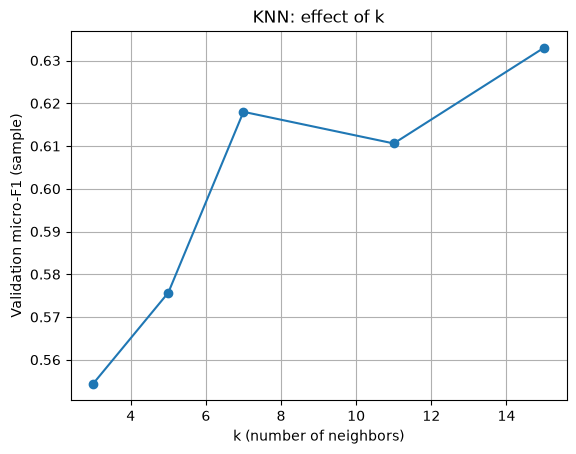

best k: 15


In [7]:
plt.plot(ks, scores, marker="o")
plt.xlabel("k (number of neighbors)")
plt.ylabel("Validation micro-F1 (sample)")
plt.title("KNN: effect of k")
plt.grid(True)
plt.savefig(FIG + "06_knn_k_search.png", dpi=150, bbox_inches="tight")
plt.show()

best_k = ks[scores.index(max(scores))]
print("best k:", best_k)

In [8]:
knn = Pipeline([
    ("prep", build_preprocessor("linear")),
    ("select", SelectKBest(f_classif, k=20)),
    ("knn", KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1)),
])

t0 = time.time()
knn.fit(X_train, y_train)
fit_time = time.time() - t0

pred_va = log_result("knn", knn, X_train, y_train, X_val, y_val, fit_time)

{'model': 'knn', 'train_micro_f1': 0.6339, 'val_micro_f1': 0.6304, 'val_macro_f1': 0.5539, 'train_time_sec': 1.6}


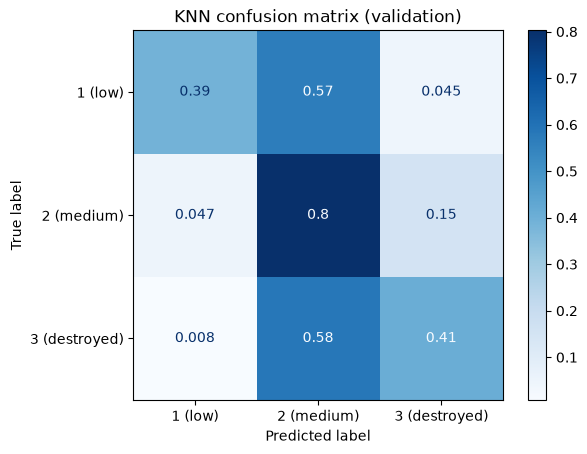

['../models/knn.joblib']

In [9]:
ConfusionMatrixDisplay.from_predictions(
    y_val, pred_va, normalize="true", cmap="Blues",
    display_labels=["1 (low)", "2 (medium)", "3 (destroyed)"])
plt.title("KNN confusion matrix (validation)")
plt.savefig(FIG + "07_knn_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

joblib.dump(knn, "../models/knn.joblib")